# Model Risiko Kredit Konsumer
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/credit-risk-model/blob/main/credit_risk_model.ipynb)

Notebook ini membangun model probability of default (PD) dari 150.000 peminjam nyata, memvalidasinya seperti praktik bank, mengubahnya menjadi cutoff skor, lalu mengestimasi expected loss, VaR, dan kerugian saat stres.

| Bagian | Isi |
|---|---|
| 0 | Asumsi dan setup |
| 1 | Data |
| 2 | Model PD dan validasi |
| 3 | Skor dan cutoff |
| 4 | Expected loss, Monte Carlo, dan stress test |
| 5 | **Hasil: ringkasan, validasi, cutoff, kerugian** |

## 0. Asumsi dan setup

Hanya ada empat asumsi, semuanya di `P`. Selebihnya berasal dari data.

| Asumsi | Nilai | Alasan |
|---|---|---|
| LGD (Loss Given Default) | 45% | Angka standar Basel untuk kredit tanpa agunan |
| EAD (Exposure at Default) | Sama untuk setiap pinjaman | Dataset tidak punya data jumlah pinjaman, jadi kerugian ditulis dalam % portofolio |
| Asset correlation ρ | 15% | Batas atas Basel untuk kredit retail; makin tinggi, makin banyak peminjam macet bersamaan saat ekonomi memburuk |
| Margin bersih | 8% per tahun | Keuntungan bank setelah dikurangi biaya, dipakai untuk menentukan cutoff skor |

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import norm
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve

P = dict(
    lgd=0.45, rho=0.15, margin=0.08,      # asumsi (lihat tabel di atas)
    pdo=20, base_score=600, base_odds=50, # skala skor: 600 poin = odds baik:buruk 50:1, +20 poin = odds 2×
    n_sims=10_000, conf=0.99, test_size=0.3, seed=42,
)

# --- Format angka Indonesia, hanya pada angka (tanda baca teks tidak diubah): 1,234.5 → 1.234,5 ---
idn = lambda s: re.sub(r"\d[\d,.]*\d", lambda a: a.group().translate(str.maketrans(",.", ".,")), s)
pct = lambda x, d=1: idn(f"{x:.{d}%}")                             # 0.0169 → "1,7%"
num = lambda x, d=3: idn(f"{x:,.{d}f}")                            # 45000 → "45.000"
status = lambda x, hijau, kuning: str(np.select([x <= hijau, x <= kuning], ["HIJAU", "KUNING"], "MERAH"))

# Nama fitur yang mudah dibaca untuk tabel dan grafik
nama_fitur = {
    "RevolvingUtilizationOfUnsecuredLines": "Pemakaian limit kredit", "age": "Usia",
    "NumberOfTime30-59DaysPastDueNotWorse": "Telat bayar 30-59 hari", "NumberOfTime60-89DaysPastDueNotWorse": "Telat bayar 60-89 hari",
    "NumberOfTimes90DaysLate": "Telat bayar 90+ hari", "DebtRatio": "Debt ratio", "MonthlyIncome": "Pendapatan bulanan",
    "NumberOfOpenCreditLinesAndLoans": "Jumlah kredit aktif", "NumberRealEstateLoansOrLines": "Jumlah kredit properti",
    "NumberOfDependents": "Jumlah tanggungan", "missingindicator_MonthlyIncome": "Pendapatan tidak diisi",
    "missingindicator_NumberOfDependents": "Tanggungan tidak diisi",
}

def tampil(judul, df, catatan=None):                               # tabel hasil: judul + tabel + cara membaca
    display(Markdown(f"**{judul}**"))
    with pd.option_context("display.max_colwidth", None):
        display(df)
    if catatan:
        display(Markdown(f"*Cara membaca:* {catatan}"))

# --- Gaya grafik siap PPT: kanvas 16:9, huruf besar, warna konsisten ---
C = dict(navy="#1F3A5F", teal="#2A9D8F", merah="#E76F51", emas="#E9A23B", abu="#8D99AE", teks="#2B2D42", latar="#F1F4F8")
warna_status = {"HIJAU": C["teal"], "KUNING": C["emas"], "MERAH": C["merah"]}
sns.set_theme(style="white", rc={
    "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.titlecolor": C["teks"], "axes.labelsize": 12, "axes.labelcolor": C["teks"], "xtick.labelsize": 11,
    "ytick.labelsize": 11, "xtick.color": C["teks"], "ytick.color": C["teks"], "axes.edgecolor": "#C8CDD3",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#E6E9ED", "legend.frameon": False, "legend.fontsize": 11, "savefig.dpi": 200})
fmt_pct = mtick.FuncFormatter(lambda v, _: pct(v, 0))             # sumbu dalam pecahan → "5%"
os.makedirs("images", exist_ok=True)                               # tempat simpan grafik (juga saat dibuka di Colab)

def slide(judul, subjudul):                                        # kanvas 16:9: judul = pesan utama
    fig = plt.figure(figsize=(13.33, 7.5))
    fig.text(0.03, 0.955, judul, fontsize=21, fontweight="bold", color=C["navy"], va="top")
    fig.text(0.03, 0.885, subjudul, fontsize=13, color=C["abu"], va="top")
    fig.text(0.03, 0.02, f"Sumber: Give Me Some Credit (OpenML), data validation {num(len(X_val), 0)} peminjam. "
             f"Asumsi: LGD {pct(P['lgd'], 0)}, korelasi {pct(P['rho'], 0)}, margin {pct(P['margin'], 0)}.",
             fontsize=9.5, color=C["abu"])
    return fig

## 1. Data

[Give Me Some Credit](https://www.openml.org/d/46929): 150.000 peminjam, 10 fitur (credit utilization, usia, riwayat tunggakan, debt ratio, pendapatan, jumlah pinjaman, tanggungan). Target adalah tunggakan serius (90+ days past due) dalam 2 tahun. Data diunduh dari OpenML dan di-cache oleh scikit-learn, tanpa perlu akun.

In [2]:
gm = fetch_openml(data_id=46929, as_frame=True).frame
y = (gm.pop("FinancialDistressNextTwoYears") == "Yes").astype(int)
kosong = gm.isna().mean()[lambda s: s > 0]
print(f"Default rate 2 tahun: {pct(y.mean(), 2)}. Data kosong: "
      + ", ".join(f"{nama_fitur[k]} {pct(v)}" for k, v in kosong.items()))

Default rate 2 tahun: 6,68%. Data kosong: Pendapatan bulanan 19,8%, Jumlah tanggungan 2,6%


## 2. Model PD dan validasi

- **Split:** 70% development, 30% validation, stratified berdasarkan target.
- **Champion: logistic regression.** Outlier dipotong di persentil 99 data development, data kosong diisi median plus missing flag, transformasi `log1p`, lalu standardisasi. Koefisiennya bisa dibaca dan diuji, karena itu bank masih memilihnya.
- **Challenger: gradient boosting** pada fitur mentah. Kalau hanya sedikit lebih baik, model yang mudah dibaca tetap dipakai.

In [3]:
X_dev, X_val, y_dev, y_val = train_test_split(gm, y, test_size=P["test_size"], stratify=y, random_state=P["seed"])
cap = X_dev.quantile(0.99)                                          # batas outlier dari data development saja
logit = make_pipeline(FunctionTransformer(lambda X: X.clip(lower=0, upper=cap, axis=1)),
                      SimpleImputer(strategy="median", add_indicator=True),
                      FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000))
gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, early_stopping=True, random_state=P["seed"])
models = {"Logistik": logit.fit(X_dev, y_dev), "Gradient boosting": gbm.fit(X_dev, y_dev)}
p_dev = {k: m.predict_proba(X_dev)[:, 1] for k, m in models.items()}
p_val = {k: m.predict_proba(X_val)[:, 1] for k, m in models.items()}

def validasi(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    return pd.Series({"AUC": auc, "Gini": 2 * auc - 1, "KS": (tpr - fpr).max(), "Brier": brier_score_loss(y, p),
                      "PD rata-rata": p.mean(), "Default rate aktual": y.mean()})

def psi(a, b, bins=10):                                             # a = acuan (development), b = pembanding
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); edges[[0, -1]] = -np.inf, np.inf
    pa, pb = (np.clip(np.histogram(x, edges)[0] / len(x), 1e-6, None) for x in (a, b))
    return ((pa - pb) * np.log(pa / pb)).sum()

val = pd.DataFrame({k: validasi(y_val, p) for k, p in p_val.items()}).T
val["AUC dev"] = [roc_auc_score(y_dev, p_dev[k]) for k in val.index]
val["PSI dev→val"] = [psi(p_dev[k], p_val[k]) for k in val.index]
coef = pd.Series(logit[-1].coef_[0], index=logit[1].get_feature_names_out(X_dev.columns)).sort_values(key=abs, ascending=False)

# Cek logika: model jauh lebih baik dari acak, PSI dua sampel identik = 0
assert (val.AUC > 0.75).all() and psi(p_dev["Logistik"], p_dev["Logistik"]) < 1e-9

## 3. Skor dan cutoff

- **PD 12 bulan:** target mencakup 2 tahun, jadi PD₁₂ = 1 − (1 − PD₂)^½.
- **Skor:** poin = 600 + 20/ln 2 × ln(odds / 50). Skor 600 berarti odds baik:buruk 50:1, dan setiap tambahan 20 poin menggandakan odds.
- **Cutoff break-even:** pinjaman menguntungkan bila margin dari pinjaman baik menutup kerugian dari pinjaman buruk, margin × (1 − PD) ≥ PD × LGD. Jadi PD₁₂ break-even = margin / (margin + LGD) = 8% / 53% ≈ 15%.
- Cutoff diuji pada sampel validation terhadap hasil **aktual**, jadi dampaknya terukur, bukan diasumsikan.

In [4]:
port = pd.DataFrame({"pd2": p_val["Logistik"], "default": y_val.to_numpy()})
port["pd12"] = 1 - (1 - port.pd2) ** 0.5
factor = P["pdo"] / np.log(2)
skor = lambda p2: P["base_score"] + factor * np.log((1 - p2) / p2 / P["base_odds"])
port["skor"] = skor(port.pd2)

pd_be = P["margin"] / (P["margin"] + P["lgd"])                      # PD12 break-even
cutoff = skor(1 - (1 - pd_be) ** 2)                                 # PD12 → PD 2 tahun → poin
port["lolos"] = port.skor >= cutoff

# Default rate aktual per desil skor: bukti model mengurutkan risiko dengan benar
port["desil"] = pd.qcut(port.skor, 10, labels=range(1, 11))
band = port.groupby("desil", observed=True).agg(pd_prediksi=("pd2", "mean"), default_aktual=("default", "mean"))
assert skor(0.01) > skor(0.2) and band.default_aktual.is_monotonic_decreasing

## 4. Expected loss, Monte Carlo, dan stress test

**Expected loss** per pinjaman adalah EL = PD₁₂ × LGD × EAD. Karena EAD sama, EL rate portofolio = rata-rata PD₁₂ × LGD.

**Model Vasicek satu faktor.** Peminjam gagal bayar bila √ρ·Z + √(1−ρ)·ε < Φ⁻¹(PD), dengan Z faktor sistemik yang sama untuk seluruh ekonomi dan ε risiko khusus peminjam itu sendiri. Untuk nilai Z tertentu, default rate portofolio besar adalah

PD(Z) = Φ( (Φ⁻¹(PD) − √ρ·Z) / √(1−ρ) )

- **Monte Carlo:** 10.000 nilai Z ~ N(0, 1), setup yang sama dengan proyek LNG. Pinjaman dikelompokkan ke 50 bucket PD agar tiap skenario cukup satu perkalian matriks kecil.
- **Cek:** pada model satu faktor, kerugian persentil 99 tepat sama dengan kerugian di Z = Φ⁻¹(1%), jadi VaR hasil simulasi harus cocok dengan rumus tertutup itu.
- **Stress test:** kerugian pada nilai Z buruk yang ditetapkan: −1 (ringan, sekitar 1 dari 6 tahun), −2 (berat, 1 dari 44 tahun), dan −3 (ekstrem, 1 dari 740 tahun).

In [5]:
def buckets(book):                                                  # ringkas buku jadi 50 bucket PD
    b = book.groupby(pd.qcut(book.pd12, 50, duplicates="drop"), observed=True)
    return b.pd12.mean().to_numpy(), b.size().to_numpy() / len(port)   # PD, porsi eksposur (vs portofolio awal)

def loss(z, book):                                                  # rugi sebagai % portofolio untuk tiap nilai Z
    pd_, w = buckets(book)
    z, r = np.atleast_1d(z)[:, None], P["rho"]
    return norm.cdf((norm.ppf(pd_) - np.sqrt(r) * z) / np.sqrt(1 - r)) @ w * P["lgd"]

def metrics(c):
    var = np.quantile(c, P["conf"])
    return pd.Series({"EL": c.mean(), "VaR 99": var, "CVaR 99": c[c >= var].mean(), "UL = VaR − EL": var - c.mean()})

Z = np.random.default_rng(P["seed"]).standard_normal(P["n_sims"])   # seed sama → skenario sama untuk dua kebijakan
lolos = port[port.lolos]
L, L_cut = loss(Z, port), loss(Z, lolos)
m = pd.DataFrame({"Tanpa cutoff": metrics(L), "Dengan cutoff": metrics(L_cut)})

stres = pd.DataFrame({"Z": [0, -1, -2, -3]}, index=["Median", "Ringan", "Berat", "Ekstrem"])
stres["1 dari N tahun"] = 1 / norm.cdf(stres.Z)
stres["Rugi tanpa cutoff"] = [loss(z, port).item() for z in stres.Z]
stres["Rugi dengan cutoff"] = [loss(z, lolos).item() for z in stres.Z]

cut = pd.Series({
    "Approval rate": port.lolos.mean(), "Bad rate aktual, semua": port.default.mean(),
    "Bad rate aktual, lolos": lolos.default.mean(), "Bad rate aktual, ditolak": port[~port.lolos].default.mean(),
})

# KRI: (nilai, batas hijau, batas kuning); AUC dibalik tanda karena makin tinggi makin baik
kri = pd.DataFrame([
    ("AUC model PD",       val.AUC["Logistik"],  0.75, 0.70, -1),   # batas umum validasi model
    ("Stabilitas skor (PSI)", val["PSI dev→val"]["Logistik"], 0.10, 0.25, 1),   # konvensi PSI industri
    ("VaR 99 tanpa cutoff", m.loc["VaR 99", "Tanpa cutoff"], 0.04, 0.06, 1),   # risk appetite (asumsi)
], columns=["KRI", "nilai", "hijau", "kuning", "arah"]).set_index("KRI")
kri["status"] = [status(r.arah * r.nilai, r.arah * r.hijau, r.arah * r.kuning) for r in kri.itertuples()]

# Cek: EL simulasi ≈ EL analitik, VaR simulasi ≈ rumus tertutup, cutoff menurunkan EL dan bad rate
assert abs(m.loc["EL", "Tanpa cutoff"] / (port.pd12.mean() * P["lgd"]) - 1) < 0.02
assert abs(m.loc["VaR 99", "Tanpa cutoff"] / loss(norm.ppf(1 - P["conf"]), port).item() - 1) < 0.03
assert cut["Bad rate aktual, lolos"] < cut["Bad rate aktual, semua"] < cut["Bad rate aktual, ditolak"]

## 5. Hasil

Setiap grafik berukuran 16:9 dengan judul berisi pesan utama, siap disalin ke slide. Tabel hanya memuat angka yang tidak ada di grafik.

### 5.1 Ringkasan

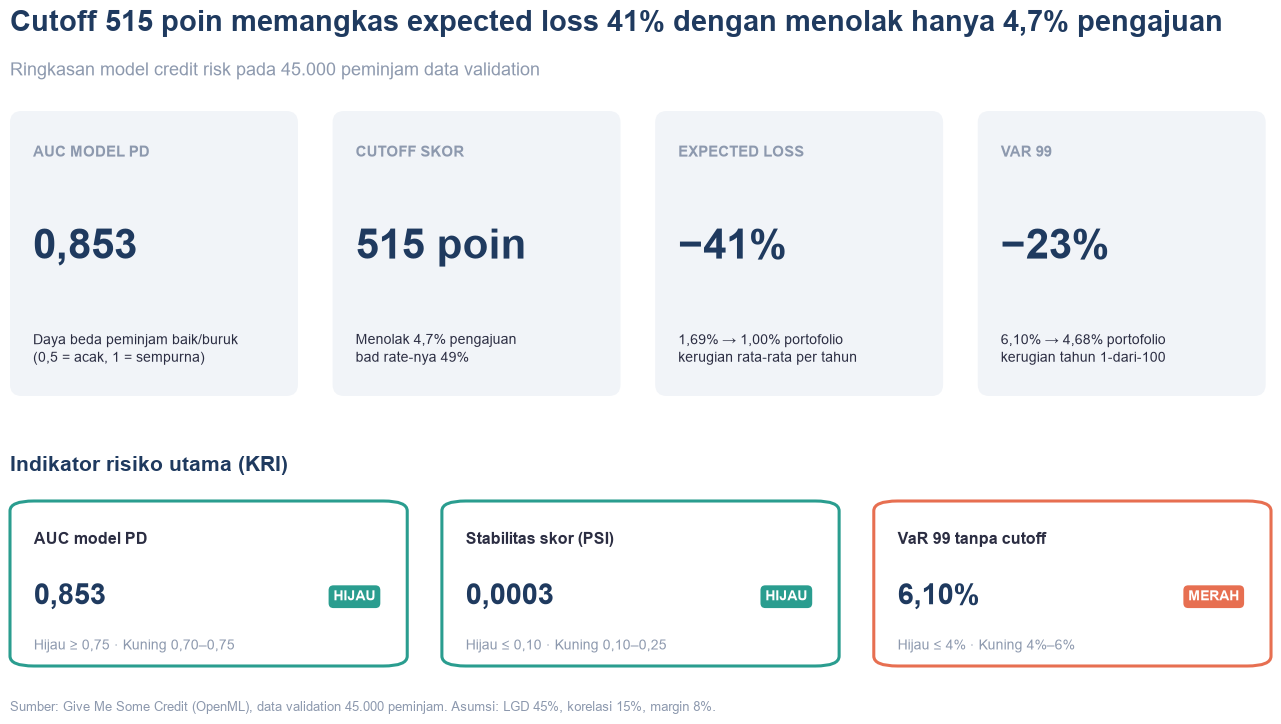

In [6]:
mt, mc = m["Tanpa cutoff"], m["Dengan cutoff"]
ap, v = cut["Approval rate"], val.loc["Logistik"]
turun = lambda a, b: pct(1 - b / a, 0)

fig = slide(f"Cutoff {cutoff:.0f} poin memangkas expected loss {turun(mt['EL'], mc['EL'])} "
            f"dengan menolak hanya {pct(1 - ap)} pengajuan",
            f"Ringkasan model credit risk pada {num(len(port), 0)} peminjam data validation")
kpi = [
    ("AUC model PD", num(v.AUC), "Daya beda peminjam baik/buruk\n(0,5 = acak, 1 = sempurna)"),
    ("Cutoff skor", f"{cutoff:.0f} poin", f"Menolak {pct(1 - ap)} pengajuan\nbad rate-nya {pct(cut['Bad rate aktual, ditolak'], 0)}"),
    ("Expected loss", f"−{turun(mt['EL'], mc['EL'])}", f"{pct(mt['EL'], 2)} → {pct(mc['EL'], 2)} portofolio\nkerugian rata-rata per tahun"),
    ("VaR 99", f"−{turun(mt['VaR 99'], mc['VaR 99'])}", f"{pct(mt['VaR 99'], 2)} → {pct(mc['VaR 99'], 2)} portofolio\nkerugian tahun 1-dari-100"),
]
for i, (lab, nilai, ket) in enumerate(kpi):                        # 4 kartu KPI, jarak simetris
    a = fig.add_axes([0.03 + i * 0.242, 0.44, 0.216, 0.38]); a.axis("off")
    a.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.04", fc=C["latar"], ec="none",
                               transform=a.transAxes, clip_on=False))
    a.text(0.08, 0.84, lab.upper(), fontsize=10.5, fontweight="bold", color=C["abu"], transform=a.transAxes)
    a.text(0.08, 0.52, nilai, fontsize=30, fontweight="bold", color=C["navy"], va="center", transform=a.transAxes)
    a.text(0.08, 0.12, ket, fontsize=10, color=C["teks"], linespacing=1.35, transform=a.transAxes)

# 3 kartu KRI: nilai, status, dan ambangnya (ambang AUC & PSI = praktik umum; ambang VaR = risk appetite, asumsi)
f_nilai = [num, lambda x: num(x, 4), lambda x: pct(x, 2)]
f_ambang = [lambda x: num(x, 2), lambda x: num(x, 2), lambda x: pct(x, 0)]
fig.text(0.03, 0.34, "Indikator risiko utama (KRI)", fontsize=15, fontweight="bold", color=C["navy"])
for i, (r, fn, fa) in enumerate(zip(kri.itertuples(), f_nilai, f_ambang)):
    a = fig.add_axes([0.03 + i * 0.324, 0.08, 0.298, 0.22]); a.axis("off")
    a.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0,rounding_size=0.06", fc="white",
                               ec=warna_status[r.status], lw=2.2, transform=a.transAxes, clip_on=False))
    a.text(0.06, 0.74, r.Index, fontsize=11.5, fontweight="bold", color=C["teks"], transform=a.transAxes)
    a.text(0.06, 0.42, fn(r.nilai), fontsize=21, fontweight="bold", color=C["navy"], va="center", transform=a.transAxes)
    a.text(0.92, 0.42, r.status, fontsize=10, fontweight="bold", color="white", ha="right", va="center",
           transform=a.transAxes, bbox=dict(boxstyle="round,pad=0.35", fc=warna_status[r.status], ec="none"))
    a.text(0.06, 0.10, f"Hijau {'≥' if r.arah < 0 else '≤'} {fa(r.hijau)} · Kuning {fa(min(r.hijau, r.kuning))}–"
           f"{fa(max(r.hijau, r.kuning))}", fontsize=10, color=C["abu"], transform=a.transAxes)
fig.savefig("images/01_ringkasan.png"); plt.show()

### 5.2 Validasi model PD

**Validasi model pada data validation**

,Logistik (champion),Gradient boosting (challenger),Acuan,Arti
Metrik,,,,
AUC,"0,853","0,864","≥ 0,75",Peluang model memberi PD lebih tinggi ke peminjam gagal bayar daripada ke peminjam lancar
Gini,"0,707","0,729","≥ 0,50","Sama dengan 2 × AUC − 1, ukuran daya beda yang lazim dipakai bank"
KS,"0,537","0,576","≥ 0,30",Jarak terbesar antara sebaran skor peminjam lancar dan gagal bayar
Brier score,"0,0503","0,0490",Makin kecil makin baik,Rata-rata kuadrat selisih PD prediksi dengan hasil aktual
AUC data development,"0,853","0,884",Dekat AUC validation,Selisih besar berarti model menghafal data latih (overfitting)
PSI development → validation,"0,0003","0,0003","< 0,10",Pergeseran sebaran skor; makin kecil makin stabil
PD rata-rata vs default aktual,"6,71% vs 6,68%","6,71% vs 6,68%",Sama,"Cek apakah level PD tepat (kalibrasi), bukan hanya urutannya"


*Cara membaca:* kedua model lolos semua acuan. Gradient boosting sedikit lebih tinggi (AUC 0,864 vs 0,853), tetapi AUC development-nya 0,884 menunjukkan sedikit overfitting dan koefisiennya tidak bisa dibaca. Karena itu logistic regression tetap dipakai sebagai model utama.

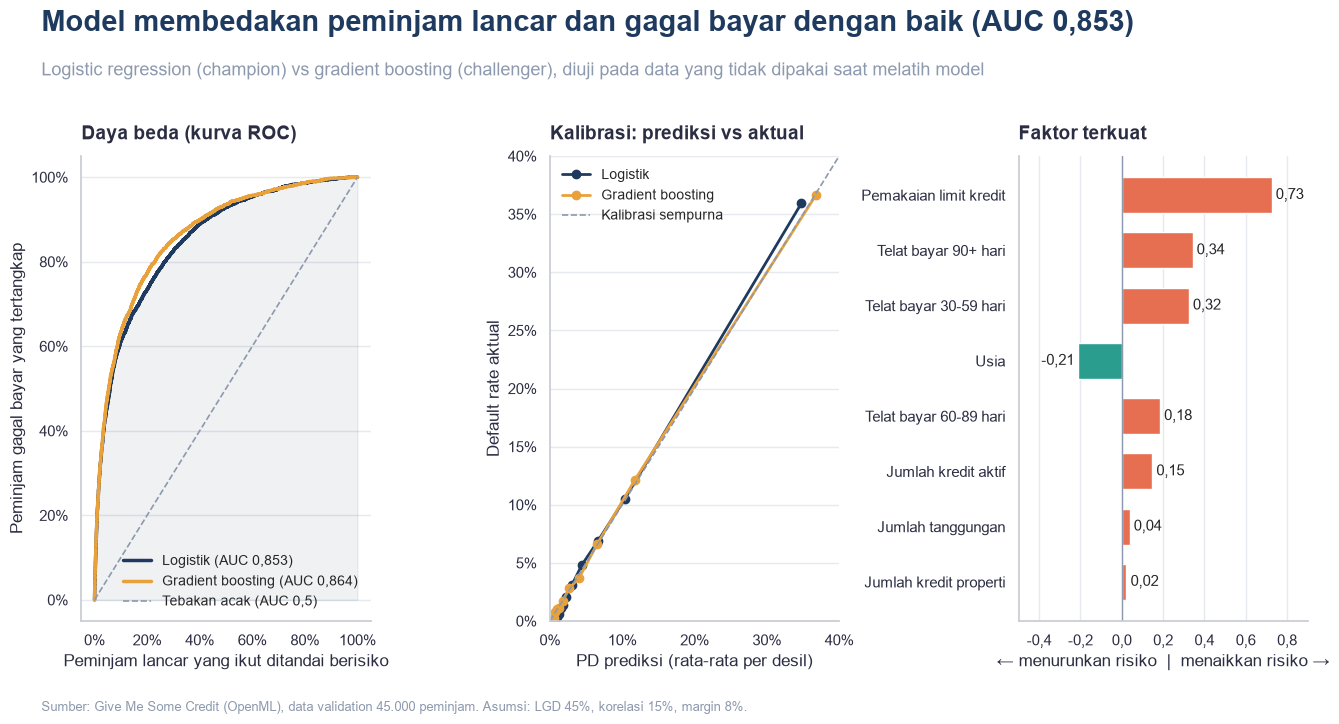

In [7]:
g = val.loc["Gradient boosting"]
baris = [("AUC", "AUC", 3, "≥ 0,75", "Peluang model memberi PD lebih tinggi ke peminjam gagal bayar daripada ke peminjam lancar"),
         ("Gini", "Gini", 3, "≥ 0,50", "Sama dengan 2 × AUC − 1, ukuran daya beda yang lazim dipakai bank"),
         ("KS", "KS", 3, "≥ 0,30", "Jarak terbesar antara sebaran skor peminjam lancar dan gagal bayar"),
         ("Brier score", "Brier", 4, "Makin kecil makin baik", "Rata-rata kuadrat selisih PD prediksi dengan hasil aktual"),
         ("AUC data development", "AUC dev", 3, "Dekat AUC validation", "Selisih besar berarti model menghafal data latih (overfitting)"),
         ("PSI development → validation", "PSI dev→val", 4, "< 0,10", "Pergeseran sebaran skor; makin kecil makin stabil")]
tabel_val = pd.DataFrame([(lab, num(v[k], d), num(g[k], d), acuan, arti) for lab, k, d, acuan, arti in baris],
                         columns=["Metrik", "Logistik (champion)", "Gradient boosting (challenger)", "Acuan", "Arti"])
tabel_val.loc[len(tabel_val)] = ["PD rata-rata vs default aktual", f"{pct(v['PD rata-rata'], 2)} vs {pct(v['Default rate aktual'], 2)}",
                                 f"{pct(g['PD rata-rata'], 2)} vs {pct(g['Default rate aktual'], 2)}", "Sama",
                                 "Cek apakah level PD tepat (kalibrasi), bukan hanya urutannya"]
tampil("Validasi model pada data validation", tabel_val.set_index("Metrik"),
       f"kedua model lolos semua acuan. Gradient boosting sedikit lebih tinggi (AUC {num(g.AUC)} vs {num(v.AUC)}), "
       f"tetapi AUC development-nya {num(g['AUC dev'])} menunjukkan sedikit overfitting dan koefisiennya tidak bisa dibaca. "
       "Karena itu logistic regression tetap dipakai sebagai model utama.")

fig = slide(f"Model membedakan peminjam lancar dan gagal bayar dengan baik (AUC {num(v.AUC)})",
            "Logistic regression (champion) vs gradient boosting (challenger), diuji pada data yang tidak dipakai saat melatih model")
ax = fig.subplots(1, 3, gridspec_kw={"width_ratios": [1, 1, 1]})
fig.subplots_adjust(top=0.76, bottom=0.14, left=0.06, right=0.98, wspace=0.62)
warna_model = {"Logistik": C["navy"], "Gradient boosting": C["emas"]}
for k, p in p_val.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    ax[0].plot(fpr, tpr, color=warna_model[k], lw=2.5, label=f"{k} (AUC {num(val.AUC[k])})")
    if k == "Logistik":
        ax[0].fill_between(fpr, tpr, color=C["navy"], alpha=0.07)
    pt, pp = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    ax[1].plot(pp, pt, "o-", color=warna_model[k], lw=2, ms=6, label=k)
ax[0].plot([0, 1], [0, 1], "--", color=C["abu"], lw=1.2, label="Tebakan acak (AUC 0,5)")
ax[0].set(title="Daya beda (kurva ROC)", xlabel="Peminjam lancar yang ikut ditandai berisiko",
          ylabel="Peminjam gagal bayar yang tertangkap")
ax[0].legend(loc="lower right", fontsize=10)
ax[1].plot([0, 0.4], [0, 0.4], "--", color=C["abu"], lw=1.2, label="Kalibrasi sempurna")
ax[1].set(title="Kalibrasi: prediksi vs aktual", xlabel="PD prediksi (rata-rata per desil)",
          ylabel="Default rate aktual", xlim=(0, 0.4), ylim=(0, 0.4))
ax[1].legend(loc="upper left", fontsize=10)
for a in ax[:2]:
    a.xaxis.set_major_formatter(fmt_pct); a.yaxis.set_major_formatter(fmt_pct)
top = coef.head(8)[::-1]
ax[2].barh(top.index.map(nama_fitur), top, color=[C["merah"] if x > 0 else C["teal"] for x in top], height=0.65)
for i, x in enumerate(top):
    ax[2].text(x + (0.02 if x > 0 else -0.02), i, num(x, 2), va="center", ha="left" if x > 0 else "right", fontsize=10.5)
ax[2].axvline(0, color=C["abu"], lw=1)
ax[2].set(title="Faktor terkuat", xlabel="← menurunkan risiko  |  menaikkan risiko →", xlim=(-0.5, 0.9), xticks=[-0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8])
ax[2].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: num(x, 1)))
ax[2].grid(axis="x", color="#E6E9ED"); ax[2].grid(axis="y", visible=False)
fig.savefig("images/02_validasi.png"); plt.show()

### 5.3 Skor dan cutoff

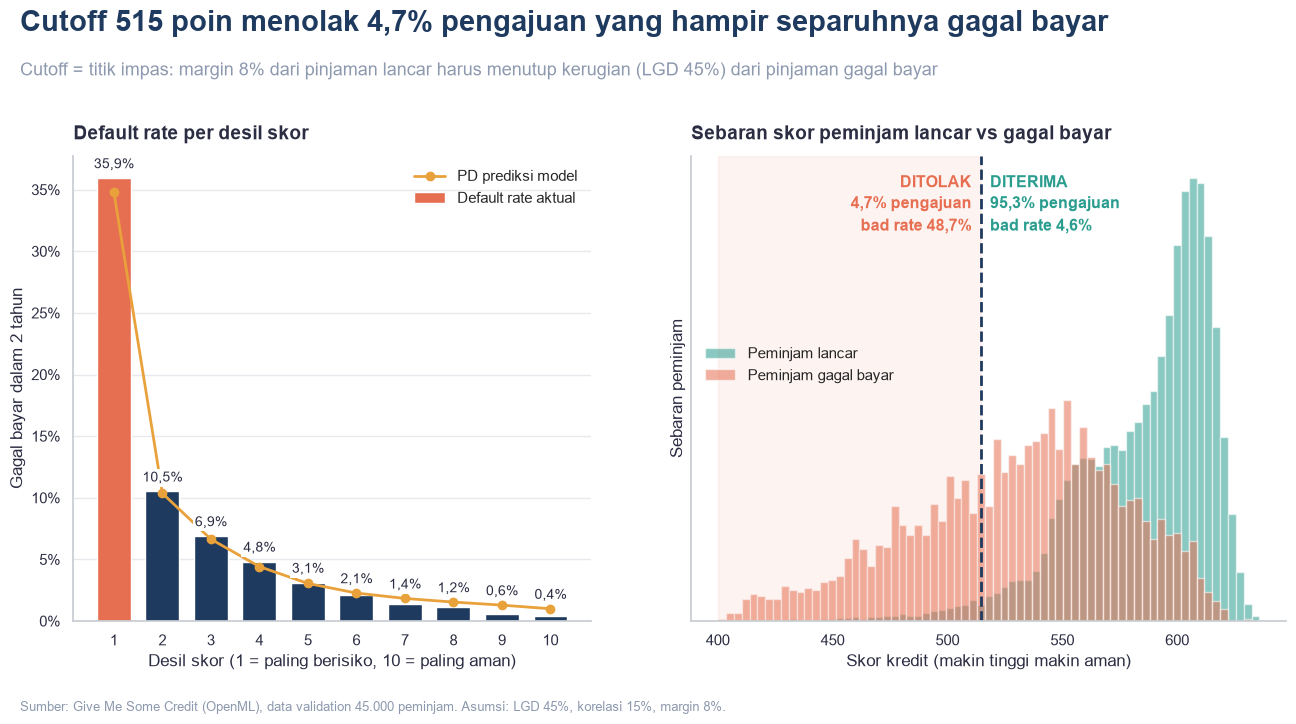

In [8]:
fig = slide(f"Cutoff {cutoff:.0f} poin menolak {pct(1 - ap)} pengajuan yang hampir separuhnya gagal bayar",
            "Cutoff = titik impas: margin 8% dari pinjaman lancar harus menutup kerugian (LGD 45%) dari pinjaman gagal bayar")
ax = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.15]})
fig.subplots_adjust(top=0.76, bottom=0.14, left=0.07, right=0.98, wspace=0.18)
x = np.arange(1, 11)
ax[0].bar(x, band.default_aktual, width=0.7, color=[C["merah"]] + [C["navy"]] * 9, label="Default rate aktual")
ax[0].plot(x, band.pd_prediksi, "o-", color=C["emas"], lw=2, ms=6, label="PD prediksi model")
for xi, d, p in zip(x, band.default_aktual, band.pd_prediksi):
    ax[0].text(xi, max(d, p) + 0.008, pct(d), ha="center", fontsize=10, color=C["teks"], zorder=5,
               bbox=dict(fc="white", ec="none", pad=1.5))
ax[0].set(title="Default rate per desil skor", xlabel="Desil skor (1 = paling berisiko, 10 = paling aman)",
          ylabel="Gagal bayar dalam 2 tahun", xticks=x)
ax[0].yaxis.set_major_formatter(fmt_pct)
ax[0].legend(loc="upper right")

bins = np.linspace(port.skor.min(), port.skor.max(), 70)
for lab, d, col in [("Peminjam lancar", port[port.default == 0], C["teal"]),
                    ("Peminjam gagal bayar", port[port.default == 1], C["merah"])]:
    ax[1].hist(d.skor, bins=bins, density=True, color=col, alpha=0.55, label=lab)
ymax = ax[1].get_ylim()[1]
ax[1].axvspan(bins[0], cutoff, color=C["merah"], alpha=0.08)
ax[1].axvline(cutoff, color=C["navy"], ls="--", lw=2)
ax[1].text(cutoff - 4, ymax * 0.97, f"DITOLAK\n{pct(1 - ap)} pengajuan\nbad rate {pct(cut['Bad rate aktual, ditolak'])}",
           ha="right", va="top", fontsize=11.5, fontweight="bold", color=C["merah"], linespacing=1.5)
ax[1].text(cutoff + 4, ymax * 0.97, f"DITERIMA\n{pct(ap)} pengajuan\nbad rate {pct(cut['Bad rate aktual, lolos'])}",
           ha="left", va="top", fontsize=11.5, fontweight="bold", color=C["teal"], linespacing=1.5)
ax[1].set(title="Sebaran skor peminjam lancar vs gagal bayar", xlabel="Skor kredit (makin tinggi makin aman)",
          ylabel="Sebaran peminjam", yticks=[])
ax[1].legend(loc="center left", bbox_to_anchor=(0, 0.55))
fig.savefig("images/03_cutoff.png"); plt.show()

### 5.4 Kerugian portofolio dan stress test

**Kerugian 12 bulan, 10.000 skenario Monte Carlo (% portofolio)**

,Tanpa cutoff,Dengan cutoff,Arti
Metrik,,,
Expected loss (EL),"1,69%","1,00%",Kerugian rata-rata per tahun; ditutup oleh cadangan (CKPN)
VaR 99,"6,10%","4,68%",Kerugian yang hanya terlampaui 1 dari 100 tahun
CVaR 99,"7,45%","5,93%",Rata-rata kerugian pada 1% tahun terburuk
Unexpected loss (UL),"4,42%","3,69%",Kerugian di atas rata-rata yang harus ditutup modal


*Cara membaca:* angka adalah persen dari total portofolio. Contoh: pada portofolio Rp 1 triliun, VaR 99 tanpa cutoff 6,10% berarti kerugian sekitar Rp 61 miliar dalam tahun 1-dari-100.

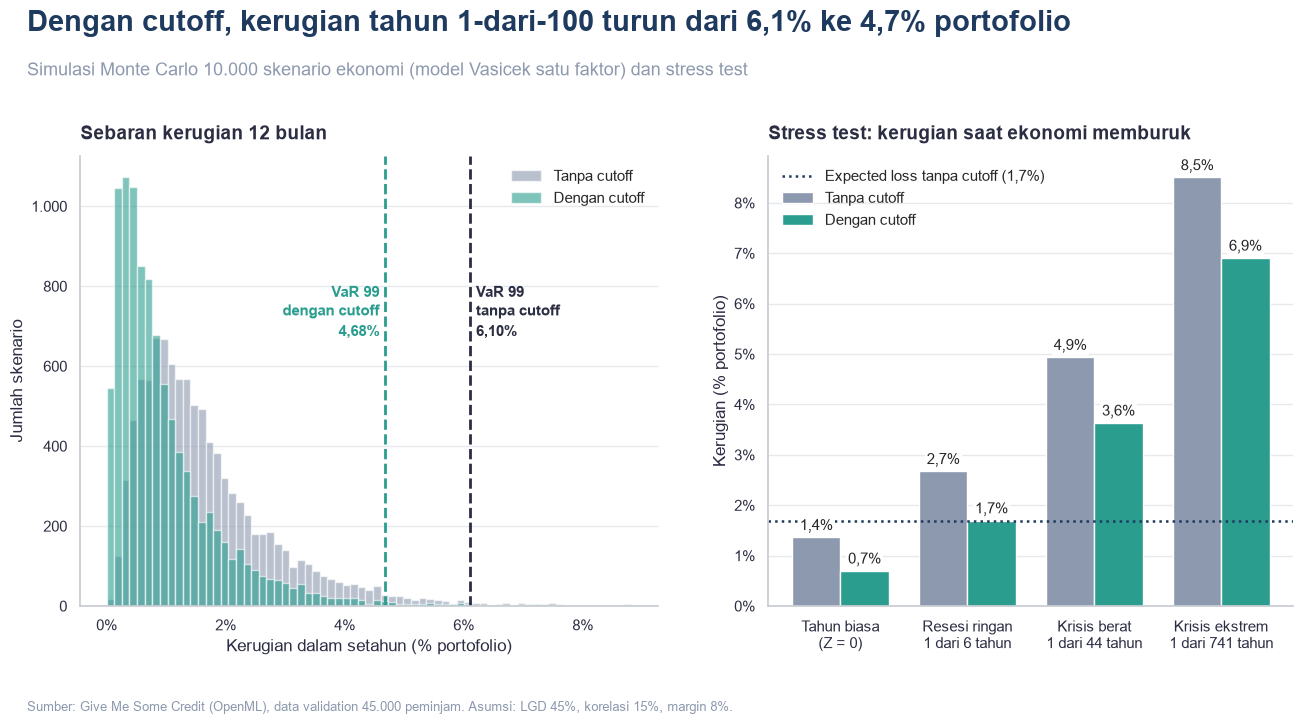

In [9]:
tampil("Kerugian 12 bulan, 10.000 skenario Monte Carlo (% portofolio)", pd.DataFrame([
    (lab, pct(mt[k], 2), pct(mc[k], 2), arti) for lab, k, arti in [
        ("Expected loss (EL)", "EL", "Kerugian rata-rata per tahun; ditutup oleh cadangan (CKPN)"),
        ("VaR 99", "VaR 99", "Kerugian yang hanya terlampaui 1 dari 100 tahun"),
        ("CVaR 99", "CVaR 99", "Rata-rata kerugian pada 1% tahun terburuk"),
        ("Unexpected loss (UL)", "UL = VaR − EL", "Kerugian di atas rata-rata yang harus ditutup modal")]
], columns=["Metrik", "Tanpa cutoff", "Dengan cutoff", "Arti"]).set_index("Metrik"),
    "angka adalah persen dari total portofolio. Contoh: pada portofolio Rp 1 triliun, VaR 99 tanpa cutoff "
    f"{pct(mt['VaR 99'], 2)} berarti kerugian sekitar Rp {num(mt['VaR 99'] * 1000, 0)} miliar dalam tahun 1-dari-100.")

nama_skenario = {"Median": "Tahun biasa", "Ringan": "Resesi ringan", "Berat": "Krisis berat", "Ekstrem": "Krisis ekstrem"}
nama_skenario = {"Median": "Tahun biasa", "Ringan": "Resesi ringan", "Berat": "Krisis berat", "Ekstrem": "Krisis ekstrem"}
fig = slide(f"Dengan cutoff, kerugian tahun 1-dari-100 turun dari {pct(mt['VaR 99'])} ke {pct(mc['VaR 99'])} portofolio",
            f"Simulasi Monte Carlo {num(P['n_sims'], 0)} skenario ekonomi (model Vasicek satu faktor) dan stress test")
ax = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1.1, 1]})
fig.subplots_adjust(top=0.76, bottom=0.16, left=0.07, right=0.98, wspace=0.2)
bins = np.linspace(0, np.quantile(L, 0.999), 70)
for c, lab, col in [(L, "Tanpa cutoff", C["abu"]), (L_cut, "Dengan cutoff", C["teal"])]:
    ax[0].hist(c, bins=bins, color=col, alpha=0.6, label=lab)
ymax = ax[0].get_ylim()[1]
for c, col, lab, ha in [(mt, C["teks"], "tanpa cutoff", "left"), (mc, C["teal"], "dengan cutoff", "right")]:
    ax[0].axvline(c["VaR 99"], color=col, ls="--", lw=2)
    ax[0].text(c["VaR 99"] + (0.001 if ha == "left" else -0.001), ymax * 0.6, f"VaR 99\n{lab}\n{pct(c['VaR 99'], 2)}",
               ha=ha, fontsize=11, fontweight="bold", color=col, linespacing=1.4)
ax[0].set(title="Sebaran kerugian 12 bulan", xlabel="Kerugian dalam setahun (% portofolio)", ylabel="Jumlah skenario")
ax[0].xaxis.set_major_formatter(fmt_pct)
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: num(x, 0)))
ax[0].legend(loc="upper right")

xs, w = np.arange(len(stres)), 0.38
for i, (k, col, lab) in enumerate([("Rugi tanpa cutoff", C["abu"], "Tanpa cutoff"), ("Rugi dengan cutoff", C["teal"], "Dengan cutoff")]):
    b = ax[1].bar(xs + (i - 0.5) * w, stres[k], w, color=col, label=lab)
    ax[1].bar_label(b, labels=[pct(x) for x in stres[k]], fontsize=10.5, padding=3,
                    bbox=dict(fc="white", ec="none", pad=1.5))
ax[1].axhline(mt["EL"], color=C["navy"], ls=":", lw=1.8, label=f"Expected loss tanpa cutoff ({pct(mt['EL'])})")
ax[1].set_xticks(xs, ["Tahun biasa\n(Z = 0)"] + [f"{nama_skenario[k]}\n1 dari {num(n, 0)} tahun"
                                                 for k, n in zip(stres.index[1:], stres["1 dari N tahun"][1:])])
ax[1].set(title="Stress test: kerugian saat ekonomi memburuk", ylabel="Kerugian (% portofolio)")
ax[1].yaxis.set_major_formatter(fmt_pct)
ax[1].legend(loc="upper left")
fig.savefig("images/04_kerugian.png"); plt.show()